In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/sram_fault_dataset.csv")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display all columns
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

Dataset shape: (450, 33)
1. sample_id
2. corner_id
3. pvt_type
4. vdd_v
5. temperature_c
6. fault_class
7. fault_name
8. fault_target
9. severity_value
10. i_ddq_uA
11. t_write_ps
12. i_write_peak_mA
13. dv_bl_strobe_mV
14. t_sense_ps
15. v_bump_mV
16. hold_pass
17. write_pass
18. read_stable_pass
19. snm_hold_v
20. snm_read_v
21. snm_asym_hold_v
22. snm_asym_read_v
23. snm_drop_v
24. is_bistable
25. iddq_norm
26. t_write_norm
27. dv_bl_norm
28. snm_hold_norm
29. snm_read_norm
30. read_write_delay_ratio
31. snm_ratio
32. dv_bl_vdd_ratio
33. converged


In [2]:
# Numerical summary
display(df.describe().T)

# Categorical summary
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
vdd_v,450.0,1.000000,0.081741,0.9000,0.900000,1.00000,1.100000,1.1000
temperature_c,450.0,37.400000,57.657850,-40.0000,0.000000,27.00000,75.000000,125.0000
fault_class,450.0,2.133333,1.232449,0.0000,1.000000,2.00000,3.000000,4.0000
severity_value,450.0,1870.333333,3090.452357,0.0000,20.000000,350.00000,2000.000000,10000.0000
i_ddq_uA,450.0,1.631988,5.080535,0.0001,0.004800,0.04180,0.730200,66.9384
t_write_ps,450.0,3392.047778,7435.583777,40.9000,59.800000,71.60000,96.250000,20000.0000
i_write_peak_mA,450.0,0.033480,0.009719,0.0170,0.024000,0.03350,0.043000,0.0890
dv_bl_strobe_mV,450.0,179.057333,104.583055,0.0000,128.025000,192.55000,245.100000,344.4000
t_sense_ps,450.0,3387.772222,7437.496558,45.4000,54.800000,65.20000,83.475000,20000.0000
v_bump_mV,450.0,187.524667,143.459568,39.0000,107.225000,131.35000,161.100000,543.5000


,count,unique,top,freq
sample_id,450,450,SRAM_F4_access_pair_S6_125C_1P1V_0450,1
corner_id,450,15,C_M40C_0P9V,30
pvt_type,450,2,ood,420
fault_name,450,5,resistive_open,180
fault_target,450,6,M5,90


In [3]:
# Unique fault classes
print(df["fault_class"].value_counts())

# Unique PVT types
print(df["pvt_type"].value_counts())

# Unique operating corners
print("Unique corners:", df["corner_id"].nunique())

# Convergence distribution
print(df["converged"].value_counts())

fault_class
1    180
4     90
3     90
2     75
0     15
Name: count, dtype: int64
pvt_type
ood                420
in_distribution     30
Name: count, dtype: int64
Unique corners: 15
converged
1    302
0    148
Name: count, dtype: int64


In [4]:
# Fault class distribution

print("FAULT CLASS DISTRIBUTION")
print(df["fault_class"].value_counts().sort_index())

print("\nFAULT NAME MAPPING")

fault_mapping = (
    df.groupby("fault_class")["fault_name"]
    .unique()
)

for fault_class, names in fault_mapping.items():
    print(f"Class {fault_class}: {names}")

FAULT CLASS DISTRIBUTION
fault_class
0     15
1    180
2     75
3     90
4     90
Name: count, dtype: int64

FAULT NAME MAPPING
Class 0: ['healthy']
Class 1: ['resistive_open']
Class 2: ['bridging']
Class 3: ['vth_drift_storage_pair']
Class 4: ['vth_drift_access']


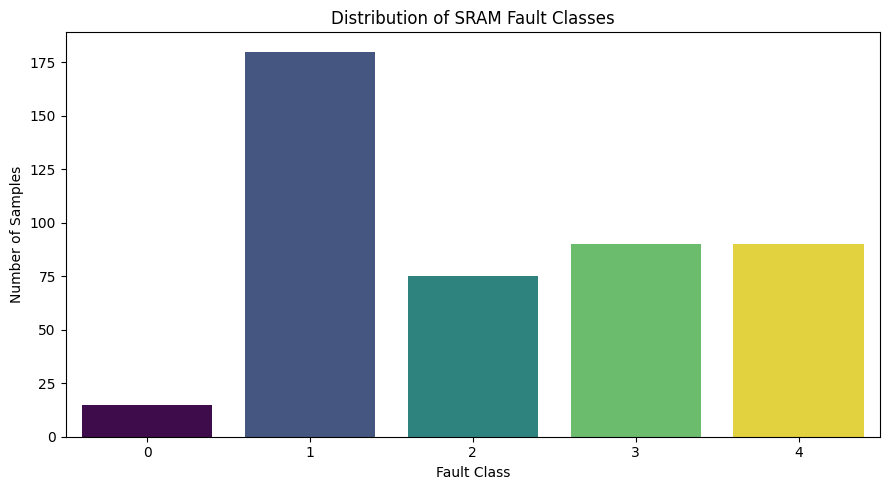

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="fault_class",
    hue="fault_class",
    palette="viridis",
    legend=False
)

plt.title("Distribution of SRAM Fault Classes")
plt.xlabel("Fault Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

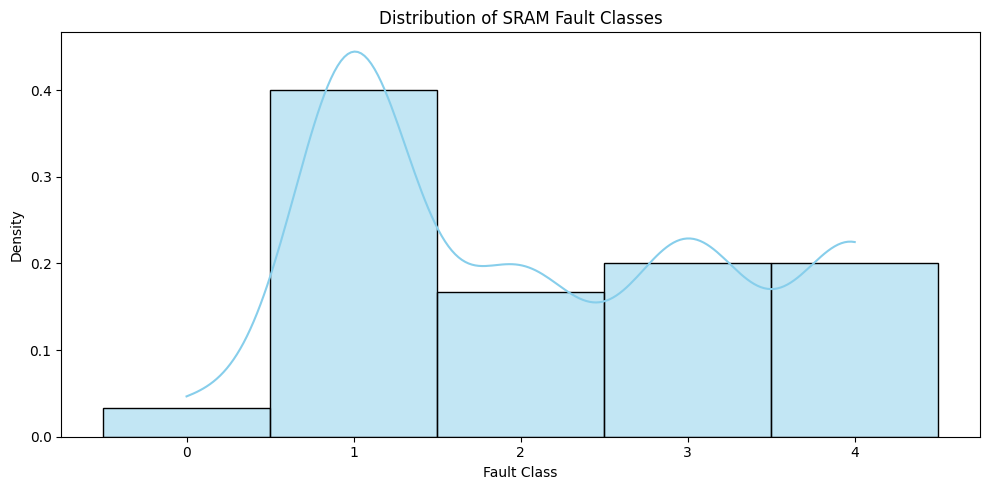

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="fault_class",
    bins=np.arange(-0.5, 5.5, 1),
    stat="density",
    kde=True,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of SRAM Fault Classes")
plt.xlabel("Fault Class")
plt.ylabel("Density")
plt.xticks([0, 1, 2, 3, 4])

plt.tight_layout()
plt.show()

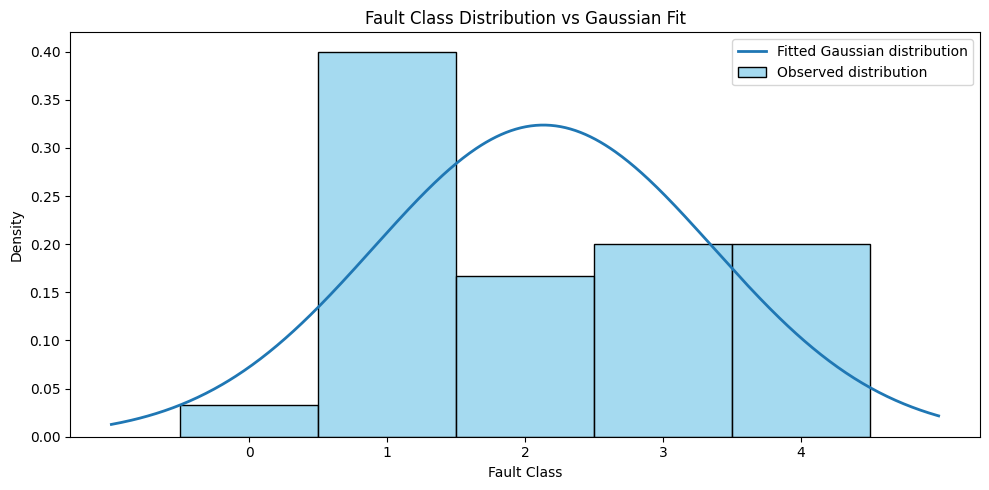

Mean: 2.1333333333333333
Standard deviation: 1.2324491704260023


In [7]:
from scipy.stats import norm

data = df["fault_class"]

mean = data.mean()
std = data.std()

x = np.linspace(-1, 5, 500)

plt.figure(figsize=(10, 5))

sns.histplot(
    data,
    bins=np.arange(-0.5, 5.5, 1),
    stat="density",
    color="skyblue",
    edgecolor="black",
    label="Observed distribution"
)

plt.plot(
    x,
    norm.pdf(x, mean, std),
    linewidth=2,
    label="Fitted Gaussian distribution"
)

plt.title("Fault Class Distribution vs Gaussian Fit")
plt.xlabel("Fault Class")
plt.ylabel("Density")
plt.legend()
plt.xticks([0, 1, 2, 3, 4])

plt.tight_layout()
plt.show()

print("Mean:", mean)
print("Standard deviation:", std)

In [8]:
print("NUMBER OF PVT CORNERS:")
print(df["corner_id"].nunique())

print("\nSAMPLES PER CORNER:")
print(df["corner_id"].value_counts().sort_index())

print("\nPVT TYPE DISTRIBUTION:")
print(df["pvt_type"].value_counts())

NUMBER OF PVT CORNERS:
15

SAMPLES PER CORNER:
corner_id
C_0C_0P9V      30
C_0C_1P0V      30
C_0C_1P1V      30
C_125C_0P9V    30
C_125C_1P0V    30
C_125C_1P1V    30
C_27C_0P9V     30
C_27C_1P0V     30
C_27C_1P1V     30
C_75C_0P9V     30
C_75C_1P0V     30
C_75C_1P1V     30
C_M40C_0P9V    30
C_M40C_1P0V    30
C_M40C_1P1V    30
Name: count, dtype: int64

PVT TYPE DISTRIBUTION:
pvt_type
ood                420
in_distribution     30
Name: count, dtype: int64


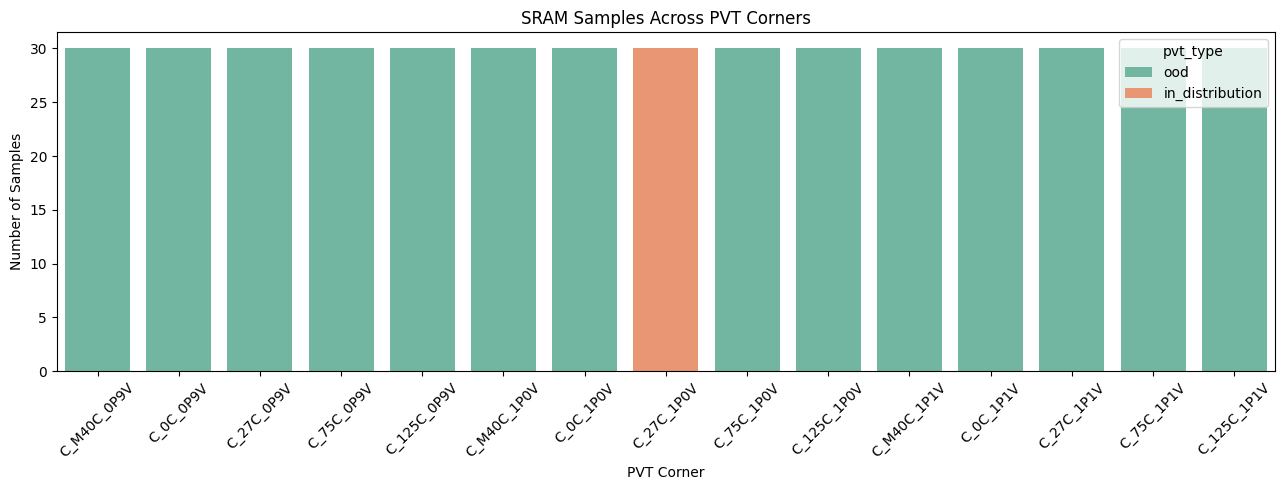

In [9]:
plt.figure(figsize=(13, 5))

sns.countplot(
    data=df,
    x="corner_id",
    hue="pvt_type",
    palette="Set2"
)

plt.title("SRAM Samples Across PVT Corners")
plt.xlabel("PVT Corner")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
print("CONVERGENCE BY FAULT CLASS")

convergence_fault = pd.crosstab(
    df["fault_class"],
    df["converged"],
    margins=True
)

print(convergence_fault)

print("\nCONVERGENCE BY PVT TYPE")

convergence_pvt = pd.crosstab(
    df["pvt_type"],
    df["converged"],
    margins=True
)

print(convergence_pvt)

CONVERGENCE BY FAULT CLASS
converged      0    1  All
fault_class               
0              3   12   15
1             21  159  180
2             75    0   75
3             33   57   90
4             16   74   90
All          148  302  450

CONVERGENCE BY PVT TYPE
converged          0    1  All
pvt_type                      
in_distribution    8   22   30
ood              140  280  420
All              148  302  450


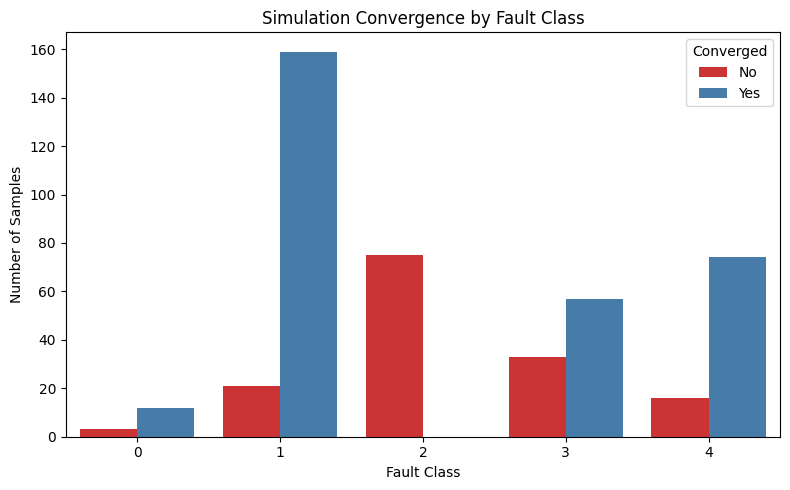

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="fault_class",
    hue="converged",
    palette="Set1"
)

plt.title("Simulation Convergence by Fault Class")
plt.xlabel("Fault Class")
plt.ylabel("Number of Samples")
plt.legend(
    title="Converged",
    labels=["No", "Yes"]
)

plt.tight_layout()
plt.show()

In [12]:
important_columns = [
    "vdd_v",
    "temperature_c",
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v"
]

print(df[important_columns].describe().T)

                 count         mean          std      min       25%       50%  \
vdd_v            450.0     1.000000     0.081741   0.9000    0.9000    1.0000   
temperature_c    450.0    37.400000    57.657850 -40.0000    0.0000   27.0000   
i_ddq_uA         450.0     1.631988     5.080535   0.0001    0.0048    0.0418   
t_write_ps       450.0  3392.047778  7435.583777  40.9000   59.8000   71.6000   
i_write_peak_mA  450.0     0.033480     0.009719   0.0170    0.0240    0.0335   
dv_bl_strobe_mV  450.0   179.057333   104.583055   0.0000  128.0250  192.5500   
t_sense_ps       450.0  3387.772222  7437.496558  45.4000   54.8000   65.2000   
v_bump_mV        450.0   187.524667   143.459568  39.0000  107.2250  131.3500   
snm_hold_v       450.0     0.364477     0.172701   0.0000    0.3697    0.4223   
snm_read_v       450.0     0.174562     0.116977   0.0000    0.0000    0.2266   

                      75%         max  
vdd_v              1.1000      1.1000  
temperature_c     75.0000   

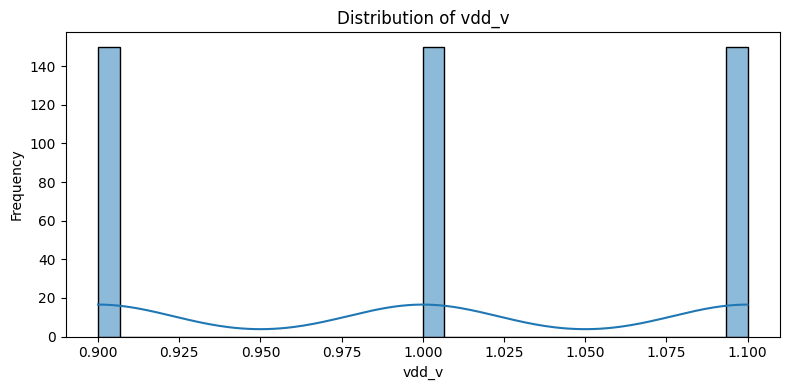

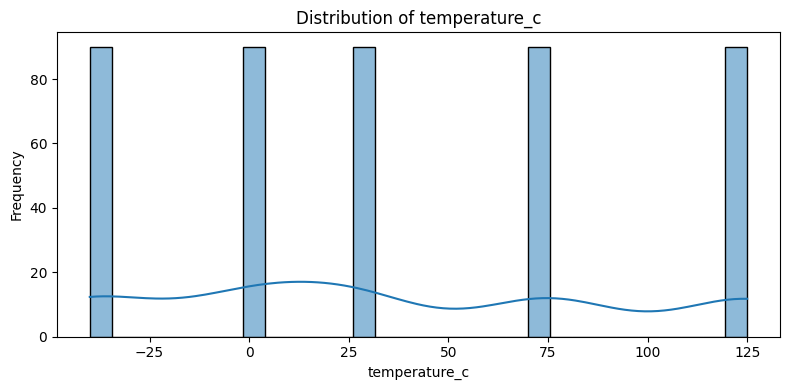

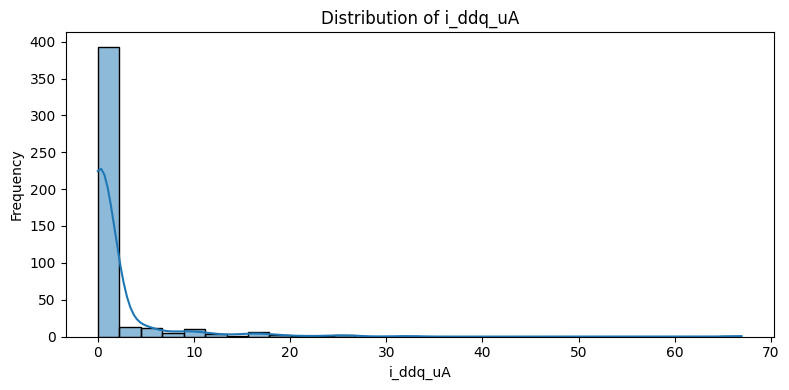

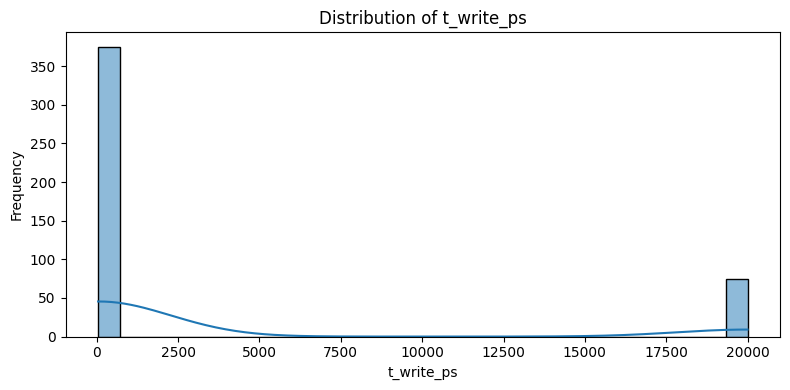

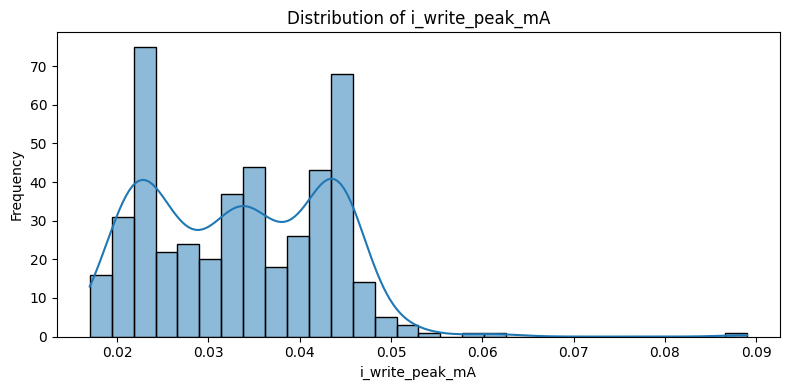

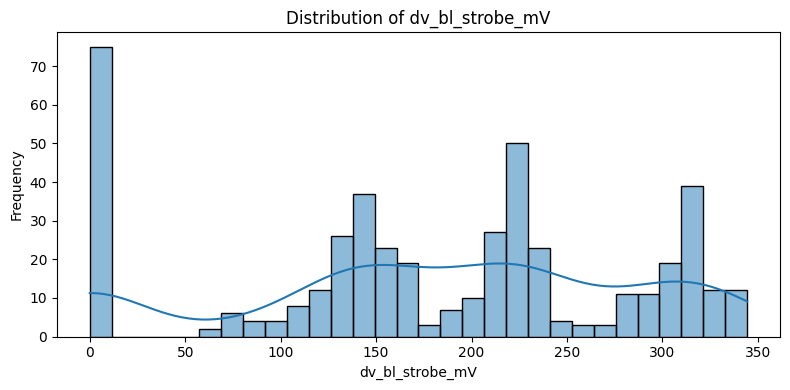

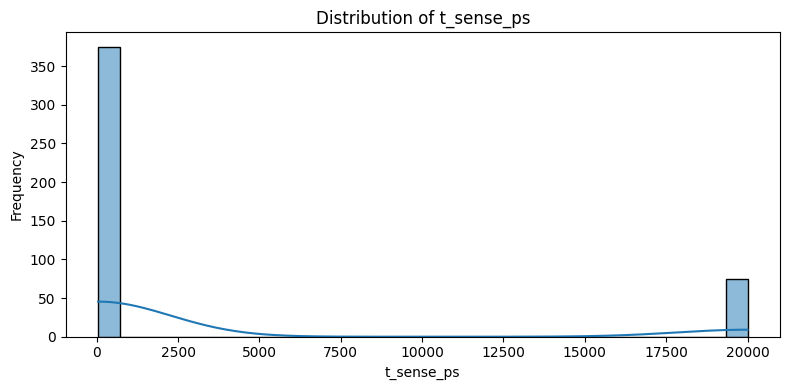

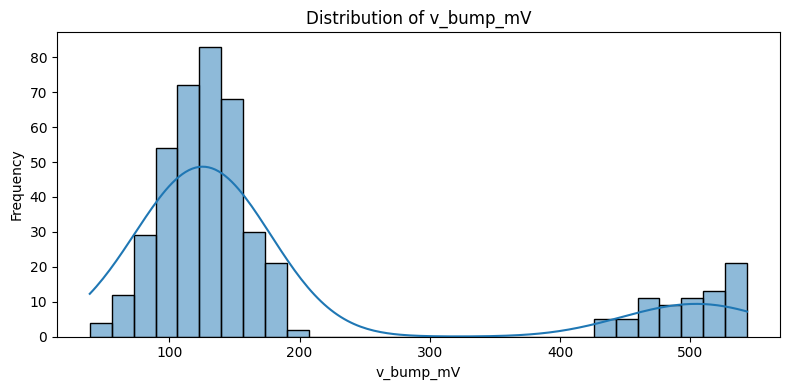

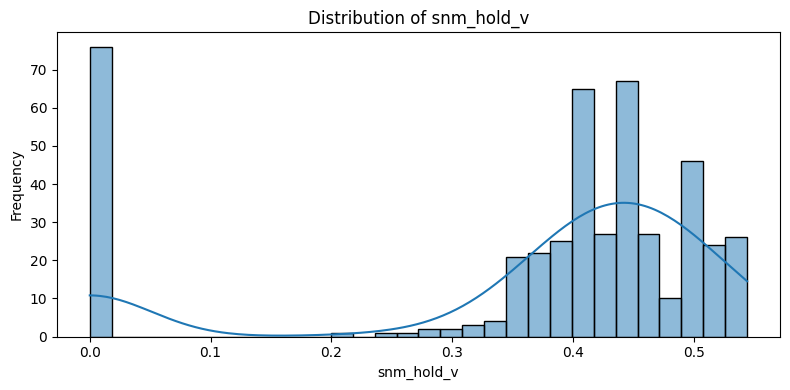

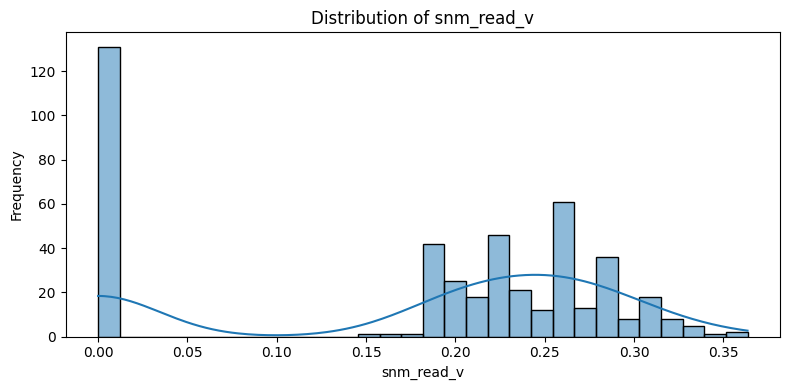

In [13]:
for col in important_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [14]:
suspicious_columns = [
    "snm_asym_hold_v",
    "snm_asym_read_v",
    "snm_drop_v",
    "t_write_ps",
    "t_sense_ps",
    "i_ddq_uA"
]

for col in suspicious_columns:

    print("\n" + "=" * 55)
    print("COLUMN:", col)

    print("Unique values:", df[col].nunique())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Zero values:", (df[col] == 0).sum())

    print("\nLargest 10 values:")
    print(df[col].nlargest(10).values)


COLUMN: snm_asym_hold_v
Unique values: 1
Minimum: 0.0
Maximum: 0.0
Zero values: 450

Largest 10 values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

COLUMN: snm_asym_read_v
Unique values: 25
Minimum: 0.0
Maximum: 0.0156
Zero values: 317

Largest 10 values:
[0.0156 0.0156 0.0091 0.0091 0.0042 0.0042 0.0039 0.0039 0.0029 0.0029]

COLUMN: snm_drop_v
Unique values: 176
Minimum: -0.2571
Maximum: 0.5368
Zero values: 75

Largest 10 values:
[0.5368 0.528  0.514  0.496  0.486  0.473  0.46   0.4501 0.4501 0.4501]

COLUMN: t_write_ps
Unique values: 252
Minimum: 40.9
Maximum: 20000.0
Zero values: 0

Largest 10 values:
[20000. 20000. 20000. 20000. 20000. 20000. 20000. 20000. 20000. 20000.]

COLUMN: t_sense_ps
Unique values: 192
Minimum: 45.4
Maximum: 20000.0
Zero values: 0

Largest 10 values:
[20000. 20000. 20000. 20000. 20000. 20000. 20000. 20000. 20000. 20000.]

COLUMN: i_ddq_uA
Unique values: 165
Minimum: 0.0001
Maximum: 66.9384
Zero values: 0

Largest 10 values:
[66.9384 31.993  26.1819 25.596  24.477  21

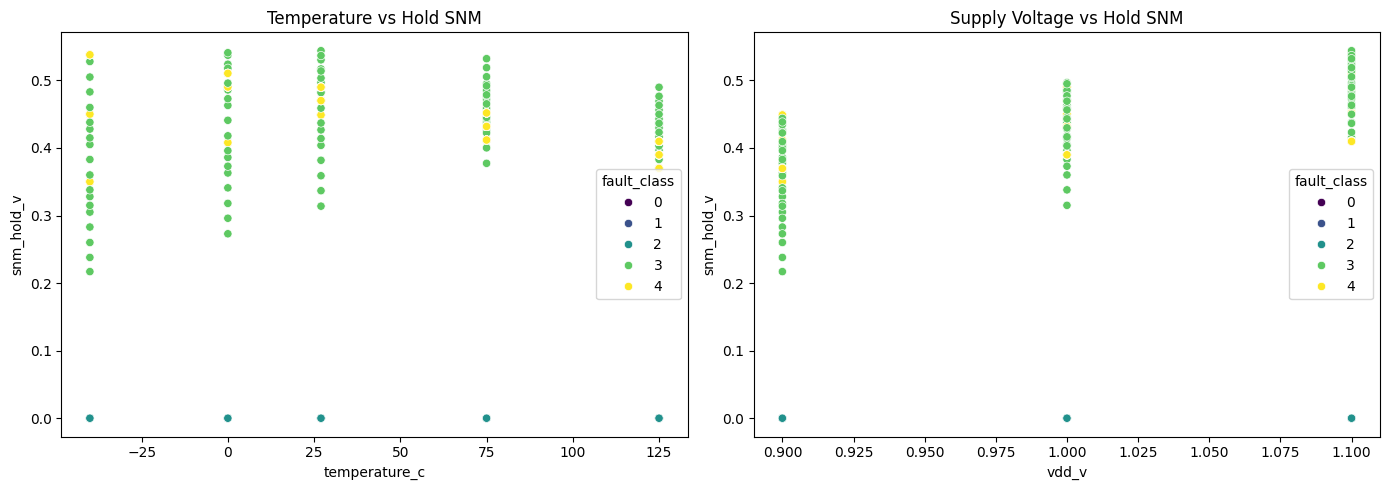

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="temperature_c",
    y="snm_hold_v",
    hue="fault_class",
    ax=axes[0],
    palette="viridis"
)

axes[0].set_title("Temperature vs Hold SNM")

sns.scatterplot(
    data=df,
    x="vdd_v",
    y="snm_hold_v",
    hue="fault_class",
    ax=axes[1],
    palette="viridis"
)

axes[1].set_title("Supply Voltage vs Hold SNM")

plt.tight_layout()
plt.show()

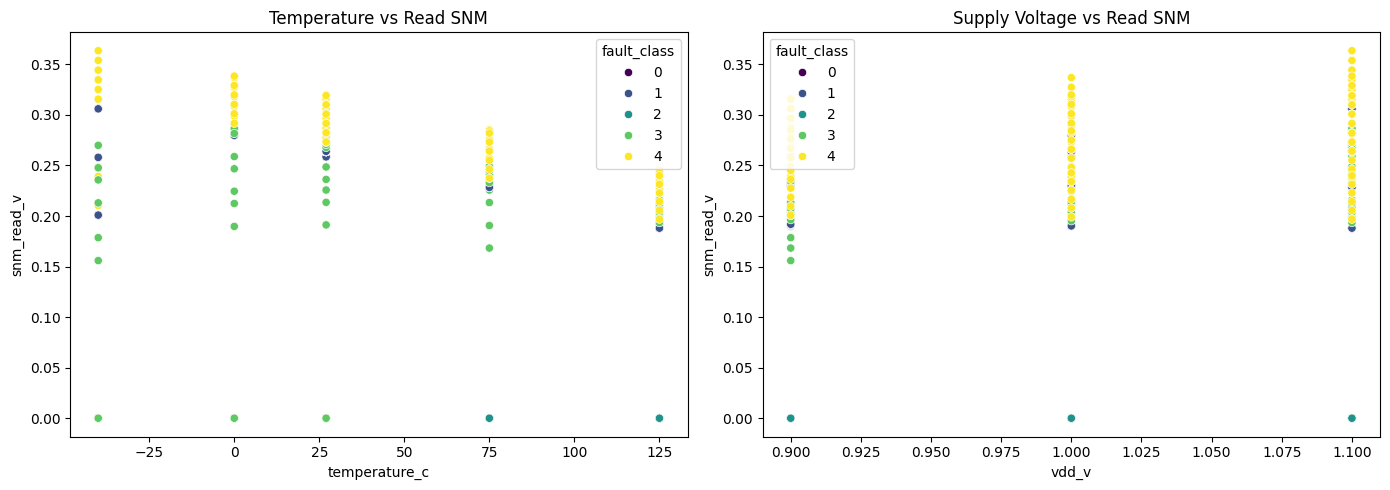

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="temperature_c",
    y="snm_read_v",
    hue="fault_class",
    ax=axes[0],
    palette="viridis"
)

axes[0].set_title("Temperature vs Read SNM")

sns.scatterplot(
    data=df,
    x="vdd_v",
    y="snm_read_v",
    hue="fault_class",
    ax=axes[1],
    palette="viridis"
)

axes[1].set_title("Supply Voltage vs Read SNM")

plt.tight_layout()
plt.show()